<a href="https://colab.research.google.com/github/yashvi02193/Fake-News-Detection-System/blob/main/Fake_News_Detection_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# AI-Powered Fake News Detection Using Text Classification
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display graphs inside the notebook
%matplotlib inline

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/fake_news_dataset.csv")

df.head()

,title,text,date,source,author,category,label
0,Foreign Democrat final.,more tax development both store agreement lawy...,2023-03-10,NY Times,Paula George,Politics,real
1,To offer down resource great point.,probably guess western behind likely next inve...,2022-05-25,Fox News,Joseph Hill,Politics,fake
2,Himself church myself carry.,them identify forward present success risk sev...,2022-09-01,CNN,Julia Robinson,Business,fake
3,You unit its should.,phone which item yard Republican safe where po...,2023-02-07,Reuters,Mr. David Foster DDS,Science,fake
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,2023-04-03,CNN,Austin Walker,Technology,fake


In [ ]:
print("Dataset Loaded Sucessfully")
print("Shape of the Dataset", df.shape)
df.dtypes
df.head()
df.tail()

Dataset Loaded Sucessfully
Shape of the Dataset (20000, 7)


,title,text,date,source,author,category,label
19995,House party born.,hit and television I change very our happy doo...,2024-12-04,BBC,Gary Miles,Entertainment,fake
19996,Though nation people maybe price box.,fear most meet rock even sea value design stan...,2024-05-26,Daily News,Maria Mcbride,Entertainment,real
19997,Yet exist with experience unit.,activity loss very provide eye west create wha...,2023-04-17,BBC,Kristen Franklin,Entertainment,real
19998,School wide itself item.,term point general common training watch respo...,2024-06-30,Reuters,David Wise,Health,fake
19999,Offer chair cover senior born.,remain pressure glass me six senior though nor...,2024-01-24,Daily News,James Peterson,Health,fake


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     20000 non-null  object
 1   text      20000 non-null  object
 2   date      20000 non-null  object
 3   source    19000 non-null  object
 4   author    19000 non-null  object
 5   category  20000 non-null  object
 6   label     20000 non-null  object
dtypes: object(7)
memory usage: 1.1+ MB


In [ ]:
# Missing Values
missing = df.isnull().sum()
print(missing)

missing_percent = (df.isnull().sum()/len(df))*100
missing_percent


title          0
text           0
date           0
source      1000
author      1000
category       0
label          0
dtype: int64


,0
title,0.0
text,0.0
date,0.0
source,5.0
author,5.0
category,0.0
label,0.0


In [ ]:
# Duplicate Records
duplicates = df.duplicated().sum()
print("Duplicate Records:", duplicates)

Duplicate Records: 0


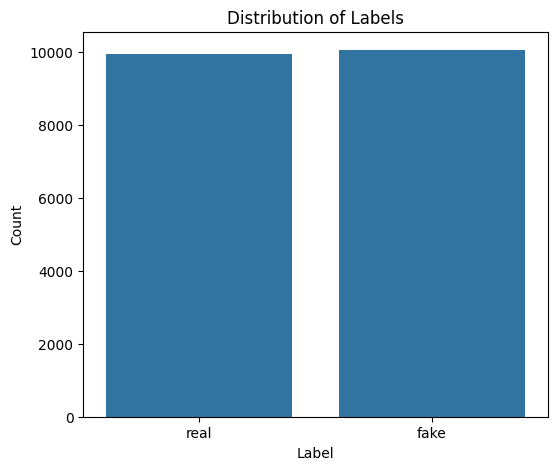

In [ ]:
# Label Distribution
df['label'].value_counts()

plt.figure(figsize=(6,5))
sns.countplot(data=df, x='label')

plt.title("Distribution of Labels")
plt.xlabel("Label")
plt.ylabel("Count")

plt.show()

In [ ]:
# Label Percentage Distribution
(df['label'].value_counts(normalize=True)*100).round(2)

,proportion
label,
fake,50.28
real,49.72


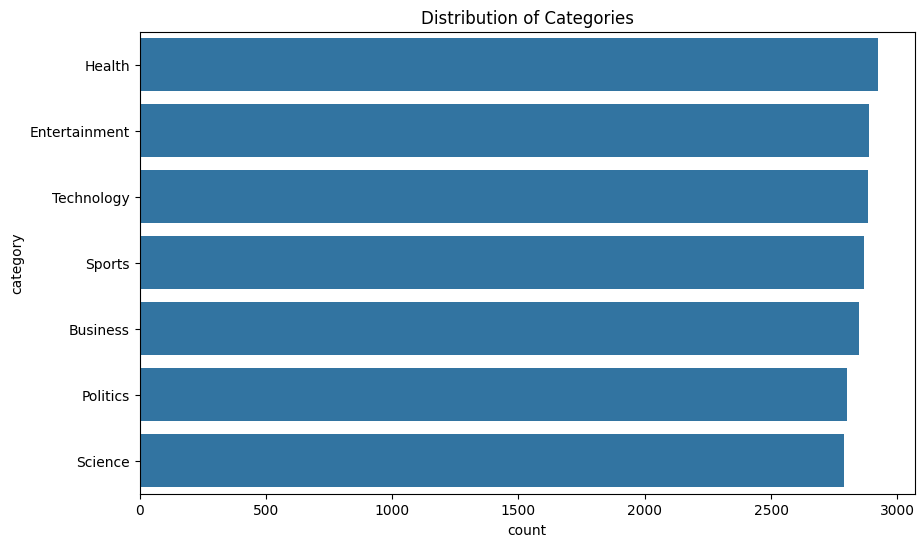

In [ ]:
# Category Distribution
df['category'].value_counts()

plt.figure(figsize=(10,6))
sns.countplot(data=df,
              y='category',
              order=df['category'].value_counts().index)

plt.title("Distribution of Categories")
plt.show()

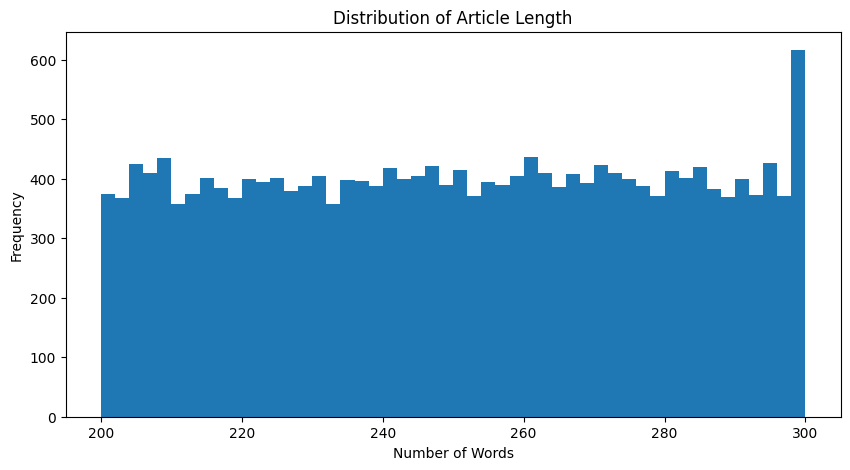

In [ ]:
# Article Length
df['Article_Length'] = df['text'].apply(lambda x: len(str(x).split()))
df[['Article_Length']].head()

# Statistics
df['Article_Length'].describe()

plt.figure(figsize=(10,5))
plt.hist(df['Article_Length'], bins=50)
plt.title("Distribution of Article Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

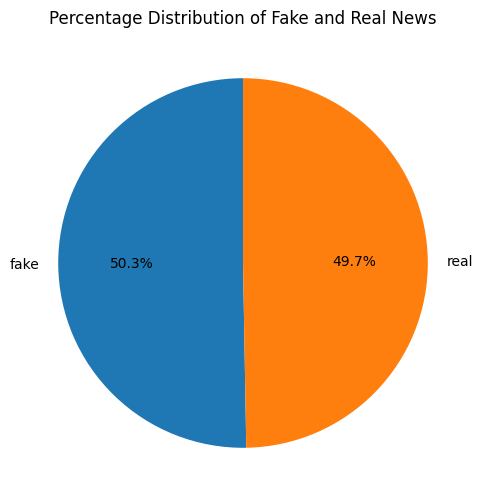

In [ ]:
# Pie chart
plt.figure(figsize=(6,6))
df['label'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.ylabel("")
plt.title("Percentage Distribution of Fake and Real News")
plt.show()

In [ ]:
# Random Samples
df.sample(5)

,title,text,date,source,author,category,label,Article_Length
7646,Though road popular better show section.,budget read choice opportunity trouble south r...,2024-02-12,BBC,NaN,Business,fake,267
5861,Daughter society ground indeed career.,movement admit pull design skin source skin da...,2023-07-16,The Guardian,Shane Hale,Sports,fake,228
17140,Throw campaign far poor get.,own church clear reveal role here animal enjoy...,2024-10-30,NaN,Jared Allen,Entertainment,real,219
5793,Energy moment strong mind young third.,purpose simple form around important this off ...,2023-08-17,BBC,Todd Soto,Health,fake,241
7941,The specific necessary space bit.,television travel charge gun catch front hot f...,2025-03-15,Reuters,David Parker,Health,fake,236


In [ ]:
# Unique Values
for col in df.columns:
  print(f"{col}: {df[col].nunique()} unique values")

title: 20000 unique values
text: 20000 unique values
date: 1096 unique values
source: 8 unique values
author: 17051 unique values
category: 7 unique values
label: 2 unique values
Article_Length: 101 unique values


In [ ]:
# Data Preprocessing
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [ ]:
# Download NLTK Resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
# Initialize stopwords and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

print("Total Stopwords:", len(stop_words))

Total Stopwords: 198


In [ ]:
# Function to clean text
def clean_text(text):

  # Convert to string
  text = str(text)

  # Convert to lowercase
  text = text.lower()

  # Remove HTML Tgas
  text = re.sub(r'<.*?>', '', text)

  # Remove URLs
  text = re.sub(r'http\S+|www\S+', '', text)

  # Remove Numbers
  text = re.sub(r'\d+', '', text)

  # Remove Punctuation
  text = text.translate(str.maketrans('','',string.punctuation))

  # Remove Special characters
  text = re.sub(r'[^a-zA-Z\s]','',text)

  # Remove Extra Spaces
  text = re.sub(r'\s+', ' ',text).strip()

  return text

In [ ]:
# Apply text cleaning
df['cleaned_text']= df['text'].apply(clean_text)
print("Text cleaned successfully")

Text cleaned successfully


In [ ]:
# Compare with the original text
comparison = df[['text', 'cleaned_text']].head(5)
comparison

,text,cleaned_text
0,more tax development both store agreement lawy...,more tax development both store agreement lawy...
1,probably guess western behind likely next inve...,probably guess western behind likely next inve...
2,them identify forward present success risk sev...,them identify forward present success risk sev...
3,phone which item yard Republican safe where po...,phone which item yard republican safe where po...
4,wonder myself fact difficult course forget exa...,wonder myself fact difficult course forget exa...


In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Tokenize the cleaned text
df['tokens'] = df['cleaned_text'].apply(word_tokenize)
print("Tokenization Completed Successfully")

df[['cleaned_text', 'tokens']].head()

Tokenization Completed Successfully


,cleaned_text,tokens
0,more tax development both store agreement lawy...,"[more, tax, development, both, store, agreemen..."
1,probably guess western behind likely next inve...,"[probably, guess, western, behind, likely, nex..."
2,them identify forward present success risk sev...,"[them, identify, forward, present, success, ri..."
3,phone which item yard republican safe where po...,"[phone, which, item, yard, republican, safe, w..."
4,wonder myself fact difficult course forget exa...,"[wonder, myself, fact, difficult, course, forg..."


In [ ]:
# Remove stopwords

df['tokens'] = df['tokens'].apply(
    lambda words: [word for word in words if word not in stop_words]
)

print("Stopwords removed successfully")

df[['cleaned_text', 'tokens']].head()

Stopwords removed successfully


,cleaned_text,tokens
0,more tax development both store agreement lawy...,"[tax, development, store, agreement, lawyer, h..."
1,probably guess western behind likely next inve...,"[probably, guess, western, behind, likely, nex..."
2,them identify forward present success risk sev...,"[identify, forward, present, success, risk, se..."
3,phone which item yard republican safe where po...,"[phone, item, yard, republican, safe, police, ..."
4,wonder myself fact difficult course forget exa...,"[wonder, fact, difficult, course, forget, exac..."


In [ ]:
# Apply Lemmatization

df['tokens'] = df['tokens'].apply(
    lambda words: [lemmatizer.lemmatize(word) for word in words]
)

print("Lemmatization Completed Successfully")

Lemmatization Completed Successfully


In [ ]:
# Convert Tokens back into Text

df['cleaned_text'] = df['tokens'].apply(lambda words: " ".join(words))

print("Cleaned text reconstructed successfully.")

Cleaned text reconstructed successfully.


In [ ]:
# Check for empty cleaned text

empty_rows = (df['cleaned_text'].str.len() == 0).sum()

print("Empty Rows:", empty_rows)

Empty Rows: 0


In [ ]:
# Save the preprocessed dataset

df.to_csv("preprocessed_fake_news.csv", index=False)

print("Preprocessed dataset saved successfully.")

Preprocessed dataset saved successfully.


In [ ]:
# Feature extraction
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [ ]:
# Intialize Bag of Words Vectorizer
bow_vectorizer = CountVectorizer(max_features=5000)
X_bow = bow_vectorizer.fit_transform(df['cleaned_text'])

print("Bag of Words Shape:", X_bow.shape)

feature_names = bow_vectorizer.get_feature_names_out()
print(feature_names[:20])

bow_df = pd.DataFrame(
    X_bow[:5].toarray(),
    columns=feature_names
)

bow_df.head()

Bag of Words Shape: (20000, 867)
['ability' 'able' 'accept' 'according' 'account' 'across' 'act' 'action'
 'activity' 'actually' 'add' 'address' 'administration' 'admit' 'adult'
 'affect' 'age' 'agency' 'agent' 'ago']


,ability,able,accept,according,account,across,act,action,activity,actually,...,would,write,writer,wrong,yard,yeah,year,yes,yet,young
0,0,0,0,0,0,1,1,0,0,0,...,1,1,0,0,0,1,0,1,0,1
1,1,0,1,0,0,0,0,0,0,1,...,0,1,1,1,1,0,0,0,0,1
2,1,0,0,0,0,0,1,0,0,0,...,0,1,0,0,1,0,0,0,0,0
3,0,0,1,0,1,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
4,1,0,0,0,0,0,0,0,1,1,...,1,0,0,0,1,1,1,0,0,0


In [ ]:
# Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(df['cleaned_text'])

print("TF-IDF Shape:", X_tfidf.shape)

tfidf_features = tfidf_vectorizer.get_feature_names_out()
print(tfidf_features[:20])

tfidf_df = pd.DataFrame(
    X_tfidf[:5].toarray(),
    columns=tfidf_features
)

tfidf_df.head()

TF-IDF Shape: (20000, 867)
['ability' 'able' 'accept' 'according' 'account' 'across' 'act' 'action'
 'activity' 'actually' 'add' 'address' 'administration' 'admit' 'adult'
 'affect' 'age' 'agency' 'agent' 'ago']


,ability,able,accept,according,account,across,act,action,activity,actually,...,would,write,writer,wrong,yard,yeah,year,yes,yet,young
0,0.000000,0.0,0.000000,0.0,0.000000,0.063203,0.062981,0.0,0.000000,0.000000,...,0.063546,0.063687,0.000000,0.000000,0.000000,0.063242,0.000000,0.063744,0.0,0.063371
1,0.060188,0.0,0.060927,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.060504,...,0.000000,0.061177,0.061673,0.061095,0.060992,0.000000,0.000000,0.000000,0.0,0.060873
2,0.063998,0.0,0.000000,0.0,0.000000,0.000000,0.064329,0.0,0.000000,0.000000,...,0.000000,0.065050,0.000000,0.000000,0.064853,0.000000,0.000000,0.000000,0.0,0.000000
3,0.000000,0.0,0.059548,0.0,0.059212,0.000000,0.000000,0.0,0.000000,0.000000,...,0.059659,0.000000,0.000000,0.000000,0.059611,0.000000,0.000000,0.000000,0.0,0.000000
4,0.063660,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.064643,0.063995,...,0.064562,0.000000,0.000000,0.000000,0.064511,0.064254,0.064672,0.000000,0.0,0.000000


In [ ]:
# Train and Test
from sklearn.model_selection import train_test_split

# Feature Matrix
X = X_tfidf

# Target Variable
y = df['label']

# Splitting into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Training Feature Shape: (16000, 867)
Testing Feature Shape: (4000, 867)
Training Labels Shape: (16000,)
Testing Labels Shape: (4000,)


In [ ]:
print("Training Labels Distribution:")
print(y_train.value_counts())

print("\nTesting Labels Distribution:")
print(y_test.value_counts())

Training Labels Distribution:
label
fake    8045
real    7955
Name: count, dtype: int64

Testing Labels Distribution:
label
fake    2011
real    1989
Name: count, dtype: int64


In [ ]:
# Model   Building
# K-Nearest Neighbours (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
# Create KNN Model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the KNN Model
knn_model.fit(X_train, y_train)
print("KNN Model Trained Successfully")

# Predicting on Testing Data
knn_predictions = knn_model.predict(X_test)

# Calculate Accuracy
knn_accuracy = accuracy_score(
    y_test,
    knn_predictions)
print("Accuracy:", round(knn_accuracy, 4))

# Calculate Precision
knn_precision = precision_score(
    y_test,
    knn_predictions,
    average="weighted"
)

print("Precision:", round(knn_precision,4))

# Calculate Recall
knn_recall = recall_score(
    y_test,
    knn_predictions,
    average="weighted"
)

print("Recall:", round(knn_recall,4))

# Calculate F1 Score
knn_f1 = f1_score(
    y_test,
    knn_predictions,
    average="weighted"
)

print("F1 Score:", round(knn_f1,4))

# Classification Report
print(classification_report(
    y_test,
    knn_predictions
))

KNN Model Trained Successfully
Accuracy: 0.5108
Precision: 0.5107
Recall: 0.5108
F1 Score: 0.5106
              precision    recall  f1-score   support

        fake       0.51      0.53      0.52      2011
        real       0.51      0.49      0.50      1989

    accuracy                           0.51      4000
   macro avg       0.51      0.51      0.51      4000
weighted avg       0.51      0.51      0.51      4000



<function matplotlib.pyplot.show(close=None, block=None)>

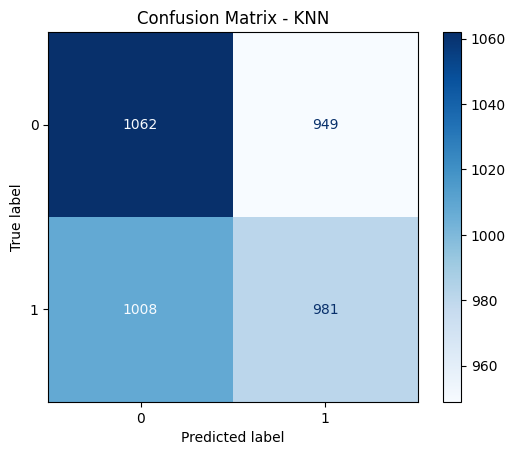

In [ ]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    knn_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - KNN")
plt.show

In [ ]:
results = []
results.append({
    "Model": "KNN",
    "Accuracy": knn_accuracy,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1 Score": knn_f1
})

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

In [ ]:
# Create Logistic Regression model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train Logistic Regression model
lr_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

# Predict on test data
lr_predictions = lr_model.predict(X_test)

# Calculate Accuracy
lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

print("Accuracy :", round(lr_accuracy,4))

# Calculate Precision
lr_precision = precision_score(
    y_test,
    lr_predictions,
    average="weighted"
)

print("Precision :", round(lr_precision,4))

# Calculate Recall
lr_recall = recall_score(
    y_test,
    lr_predictions,
    average="weighted"
)

print("Recall :", round(lr_recall,4))

# Calculate F1 Score
lr_f1 = f1_score(
    y_test,
    lr_predictions,
    average="weighted"
)

print("F1 Score :", round(lr_f1,4))

# Classification Report
print(classification_report(
    y_test,
    lr_predictions
))

Logistic Regression model trained successfully!
Accuracy : 0.5025
Precision : 0.5024
Recall : 0.5025
F1 Score : 0.5023
              precision    recall  f1-score   support

        fake       0.51      0.52      0.51      2011
        real       0.50      0.48      0.49      1989

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000



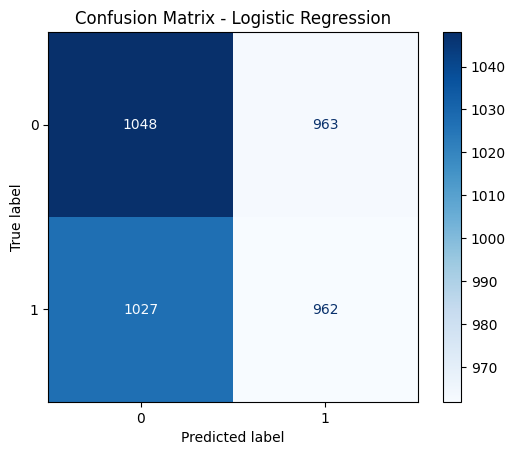

In [ ]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    lr_predictions
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [ ]:
# Store Results
results.append({
    "Model": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1 Score": lr_f1
})

In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Random Forest model
rf_model.fit(X_train, y_train)
print("Random Forest model trained succesfully")

Random Forest model trained succesfully


In [ ]:
# Predict on test data
rf_predictions = rf_model.predict(X_test)

# Calculate Accuracy
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print("Accuracy :", round(rf_accuracy,4))

# Calculate Precision
rf_precision = precision_score(
    y_test,
    rf_predictions,
    average="weighted"
)

print("Precision :", round(rf_precision,4))

# Calculate Recall
rf_recall = recall_score(
    y_test,
    rf_predictions,
    average="weighted"
)

print("Recall :", round(rf_recall,4))

# Calculate F1-Score
rf_f1 = f1_score(
    y_test,
    rf_predictions,
    average="weighted"
)

print("F1 Score :", round(rf_f1,4))

# Classification Report
print(classification_report(
    y_test,
    rf_predictions
))

Accuracy : 0.5018
Precision : 0.5015
Recall : 0.5018
F1 Score : 0.5
              precision    recall  f1-score   support

        fake       0.50      0.56      0.53      2011
        real       0.50      0.44      0.47      1989

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000



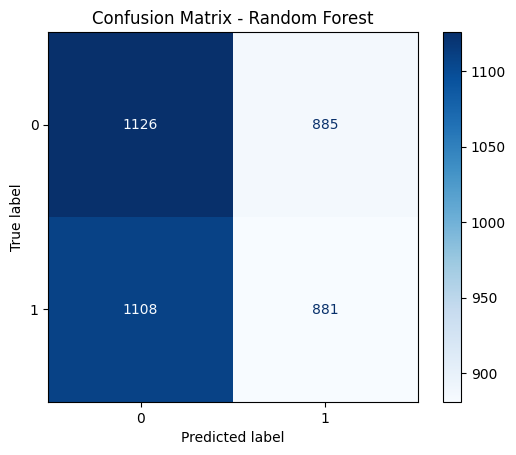

In [ ]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    rf_predictions
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.show()

In [ ]:
# Results Stored
results.append({
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1 Score": rf_f1
})

In [ ]:
# Neural Network
from sklearn.neural_network import MLPClassifier

In [ ]:
# Create Neural Network model
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

# Train Neural Network model
mlp_model.fit(X_train, y_train)

print("Neural Network model trained successfully!")

# Predict on test data
mlp_predictions = mlp_model.predict(X_test)

# Calculate Accuracy
mlp_accuracy = accuracy_score(
    y_test,
    mlp_predictions
)

print("Accuracy :", round(mlp_accuracy,4))

# Calculate Precision
mlp_precision = precision_score(
    y_test,
    mlp_predictions,
    average="weighted"
)

print("Precision :", round(mlp_precision,4))

# Calculate Recall
mlp_recall = recall_score(
    y_test,
    mlp_predictions,
    average="weighted"
)

print("Recall :", round(mlp_recall,4))

# Calculate F1-Score
mlp_f1 = f1_score(
    y_test,
    mlp_predictions,
    average="weighted"
)

print("F1 Score :", round(mlp_f1,4))

# Classification Report
print(classification_report(
    y_test,
    mlp_predictions
))

Neural Network model trained successfully!
Accuracy : 0.5005
Precision : 0.5006
Recall : 0.5005
F1 Score : 0.5004
              precision    recall  f1-score   support

        fake       0.50      0.49      0.49      2011
        real       0.50      0.51      0.51      1989

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000



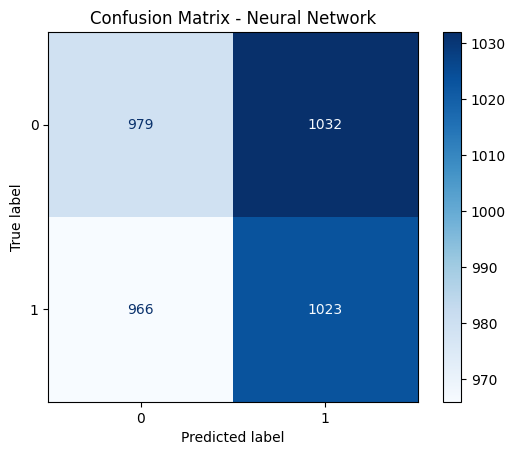

In [ ]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    mlp_predictions
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Neural Network")
plt.show()

In [ ]:
# Results Stored
results.append({
    "Model": "Neural Network",
    "Accuracy": mlp_accuracy,
    "Precision": mlp_precision,
    "Recall": mlp_recall,
    "F1 Score": mlp_f1
})

In [ ]:
# Comparison of Different Modesl
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.51075,0.510680,0.51075,0.510604
1,Logistic Regression,0.50250,0.502415,0.50250,0.502329
2,Random Forest,0.50175,0.501462,0.50175,0.500042
3,Neural Network,0.50050,0.500591,0.50050,0.500409


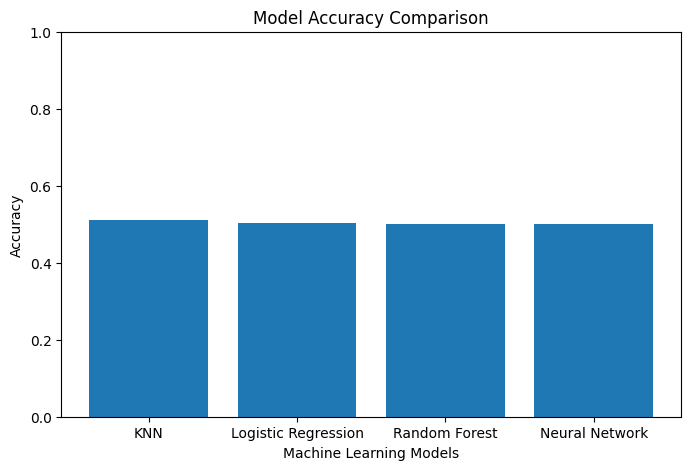

In [ ]:
# Accuracy Graph
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.show()

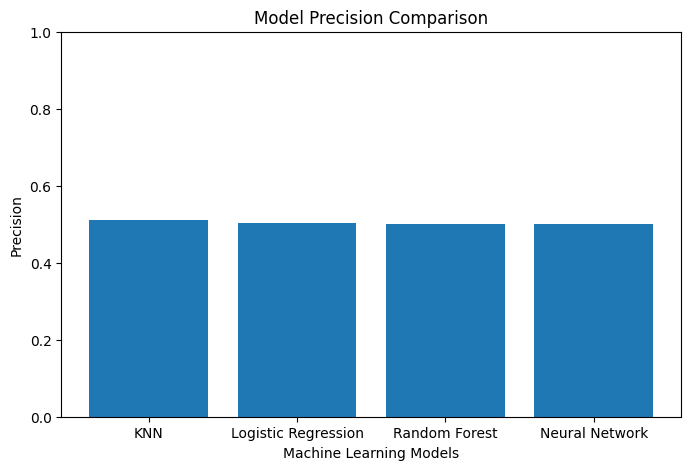

In [ ]:
# Precision Graph
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["Precision"])
plt.title("Model Precision Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Precision")
plt.ylim(0,1)
plt.show()

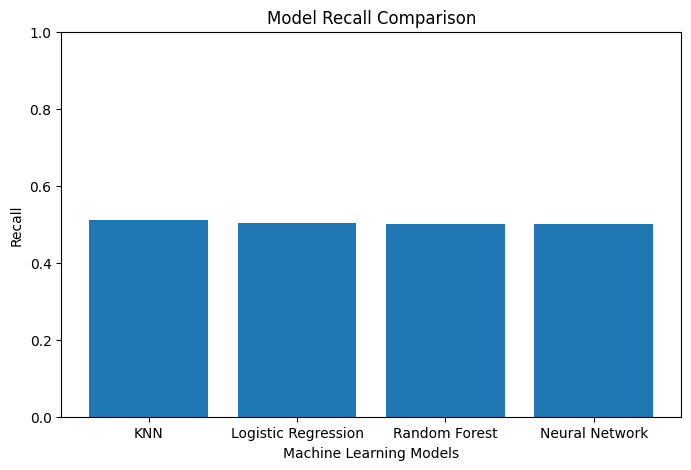

In [ ]:
# Recall Graph
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["Recall"])
plt.title("Model Recall Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Recall")
plt.ylim(0,1)
plt.show()

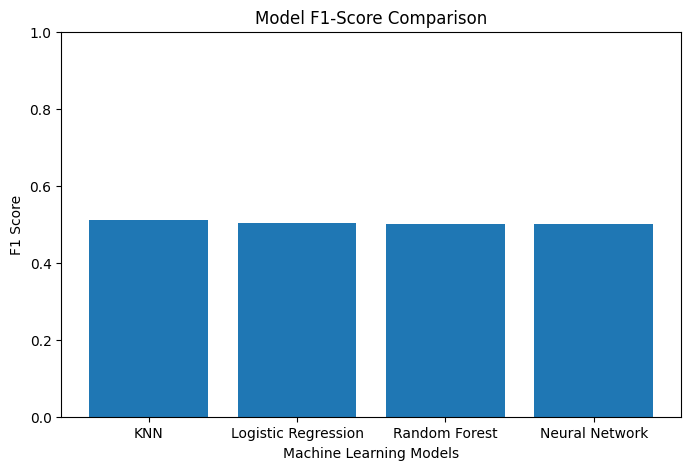

In [ ]:
# F1 Graph
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["F1 Score"])
plt.title("Model F1-Score Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.ylim(0,1)
plt.show()

In [ ]:
best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]
print("Best Performing Model")
(best_model)

Best Performing Model


,0
Model,KNN
Accuracy,0.51075
Precision,0.51068
Recall,0.51075
F1 Score,0.510604


In [ ]:
results_df.to_csv(
    "Model_Comparison.csv",
    index=False
)
print("Comparison table saved successfully.")

Comparison table saved successfully.
